# Multi-account Brinson attribution: three decision views

This tutorial compares three methods using **one wholly synthetic dataset**:

1. **Macro → Micro:** attribute account allocation, then explain each account's active return with within-account Brinson.
2. **Value-weighted total portfolio:** pool holdings, then run one portfolio-level Brinson.
3. **Hierarchical decision attribution:** benchmark → account weights → sector weights → security weights → security returns.

Amounts are beginning-of-period market values or benchmark notionals; returns, weights and effects are decimal values. No real securities, trades, transfers, cash flows or fees are represented. See `docs/source/multi-account.md` for all equations.

In [1]:
from pathlib import Path
import sys
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "brinsons").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Launch Jupyter from the project root or tutorials/ directory")
sys.path.insert(0, str(ROOT / "src"))
from brinsons import (
    macro_micro_attribution, value_weighted_total_attribution,
    hierarchical_decision_attribution, link_macro_micro_attribution,
    link_hierarchical_decision_attribution, link_carino, link_grap,
    link_frongello, link_menchero, bhb,
)
DATA = ROOT / "data" / "multi_account" / "positions.csv"
positions = pl.read_csv(DATA)
print(f"Loaded {positions.height} synthetic observations from {DATA}")
display(positions.head(8))

Loaded 36 synthetic observations from D:\Python\brinson\data\multi_account\positions.csv


period,account,sector,security,portfolio_value,benchmark_value,portfolio_return,benchmark_return
str,str,str,str,f64,f64,f64,f64
"""2026-01""","""Global""","""Healthcare""","""HLTH_A""",484000.0,600000.0,0.014,0.012
"""2026-01""","""Global""","""Healthcare""","""HLTH_B""",396000.0,650000.0,0.0185,0.018
"""2026-01""","""Global""","""Technology""","""TECH_A""",683200.0,575000.0,0.043,0.04
"""2026-01""","""Global""","""Technology""","""TECH_B""",436800.0,675000.0,0.0265,0.025
"""2026-01""","""Growth""","""Healthcare""","""HLTH_A""",928000.0,936000.0,0.011,0.012
"""2026-01""","""Growth""","""Healthcare""","""HLTH_B""",672000.0,864000.0,0.0155,0.018
"""2026-01""","""Growth""","""Technology""","""TECH_A""",1.8700e6,1.1e6,0.045,0.04
"""2026-01""","""Growth""","""Technology""","""TECH_B""",1.53e6,1.1e6,0.0285,0.025


## 0. Validate the input hierarchy

Each period should contain 3 accounts × 2 sectors × 2 synthetic securities. Portfolio market value and benchmark notional each total 10 million, with well-defined conditional weights on both sides.

In [2]:
value_check = positions.group_by("period", "account").agg(
    pl.col("portfolio_value", "benchmark_value").sum()
).sort("period", "account")
display(value_check)
assert value_check.height == 9
assert positions.select(pl.struct("period", "account", "sector", "security").is_duplicated().any()).item() is False

period,account,portfolio_value,benchmark_value
str,str,f64,f64
"""2026-01""","""Global""",2e6,2.5e6
"""2026-01""","""Growth""",5e6,4e6
"""2026-01""","""Income""",3e6,3.5e6
"""2026-02""","""Global""",2e6,2.5e6
"""2026-02""","""Growth""",4.5e6,4e6
"""2026-02""","""Income""",3.5e6,3.5e6
"""2026-03""","""Global""",2.5e6,2.5e6
"""2026-03""","""Growth""",4e6,4e6
"""2026-03""","""Income""",3.5e6,3.5e6


## 1. Macro account allocation → Micro Brinson within each account

First treat accounts as Brinson categories. The default is three-effect BF:

$$A_a^{macro}=(W^P_a-W^B_a)(R^B_a-R_B),\quad
S_a^{macro}=W^B_a(R^P_a-R^B_a),\quad
I_a^{macro}=(W^P_a-W^B_a)(R^P_a-R^B_a).$$

Then run BF by sector inside each account. In the integrated result, the portfolio-account-weighted micro effects **replace** $S_a^{macro}+I_a^{macro}=W^P_a(R^P_a-R^B_a)$, avoiding double counting.

In [3]:
macro_micro = macro_micro_attribution(positions)
print("Account-level macro effects")
display(macro_micro.macro.detail.select(
    "period", "account", "_ma_wp", "_ma_wb", "_ma_rp", "_ma_rb",
    "allocation", "selection", "interaction"
).head(9))
print("Within-account micro Brinson")
display(macro_micro.micro_summary.head(9))
print("Integrated total")
display(macro_micro.integrated_summary)

Account-level macro effects


period,account,_ma_wp,_ma_wb,_ma_rp,_ma_rb,allocation,selection,interaction
str,str,f64,f64,f64,f64,f64,f64,f64
"""2026-01""","""Global""",0.2,0.25,0.0275274,0.02351,0.000008,0.001004,-0.000201
"""2026-01""","""Growth""",0.5,0.4,0.029676,0.024571,0.000091,0.002042,0.00051
"""2026-01""","""Income""",0.3,0.35,0.0244936,0.02274,0.000046,0.000614,-0.000088
"""2026-02""","""Global""",0.2,0.25,-0.000246,0.0006,-0.000006,-0.000212,0.000042
"""2026-02""","""Growth""",0.45,0.4,-0.003766,-0.001096,-0.000079,-0.001068,-0.000134
"""2026-02""","""Income""",0.35,0.35,0.004627,0.002222,0.0,0.000842,0.0
"""2026-03""","""Global""",0.25,0.25,0.0192,0.01472,-0.0,0.00112,0.0
"""2026-03""","""Growth""",0.4,0.4,0.023741,0.015958,0.0,0.003113,0.0
"""2026-03""","""Income""",0.35,0.35,0.013388,0.013353,-0.0,0.000012,0.0


Within-account micro Brinson


period,allocation,selection,interaction,portfolio_return,benchmark_return,excess_return,account,account_portfolio_weight
str,f64,f64,f64,f64,f64,f64,str,f64
"""2026-01""",0.0010068,0.002785,0.000226,0.027527,0.02351,0.004017,"""Global""",0.2
"""2026-01""",0.002291,0.001896,0.000918,0.0296758,0.024571,0.0051048,"""Growth""",0.5
"""2026-01""",-0.000172,0.001907,0.000019,0.024494,0.02274,0.001754,"""Income""",0.3
"""2026-02""",-0.002605,0.001787,-0.000029,-0.000247,0.0006,-0.000847,"""Global""",0.2
"""2026-02""",-0.004968,0.001581,0.000716,-0.003766,-0.001096,-0.00267,"""Growth""",0.45
"""2026-02""",0.000985,0.001262,0.000158,0.004627,0.002222,0.002405,"""Income""",0.35
"""2026-03""",0.002592,0.0015275,0.00036,0.0192,0.01472,0.00448,"""Global""",0.25
"""2026-03""",0.004549,0.001983,0.001251,0.023741,0.015958,0.007783,"""Growth""",0.4
"""2026-03""",-0.001317,0.00123,0.000122,0.013388,0.013353,0.000035,"""Income""",0.35


Integrated total


period,account_allocation,weighted_micro_allocation,weighted_micro_selection,weighted_micro_interaction,total_effect,portfolio_return,benchmark_return,excess_return
str,f64,f64,f64,f64,f64,f64,f64,f64
"""2026-01""",0.000145,0.001295,0.002077,0.00051,0.004027,0.027691,0.023665,0.004027
"""2026-02""",-0.000085,-0.002412,0.001511,0.000372,-0.000614,-0.000125,0.000489,-0.000614
"""2026-03""",0.0,0.002007,0.001605,0.000633,0.004246,0.018982,0.014737,0.004246


In [4]:
account_check = macro_micro.integrated_detail.with_columns(
    (pl.col("macro_selection") + pl.col("macro_interaction")).alias("macro_active"),
    pl.sum_horizontal("weighted_micro_allocation", "weighted_micro_selection",
                      "weighted_micro_interaction").alias("micro_replacement")
)
assert max(abs(x) for x in account_check.select(
    pl.col("macro_active") - pl.col("micro_replacement")).to_series()) < 1e-12
display(account_check.select("period", "account", "account_allocation",
                             "macro_active", "micro_replacement", "total_effect").head(9))

period,account,account_allocation,macro_active,micro_replacement,total_effect
str,str,f64,f64,f64,f64
"""2026-01""","""Global""",0.000008,0.000803,0.000803,0.000811
"""2026-01""","""Growth""",0.000091,0.002552,0.002552,0.002643
"""2026-01""","""Income""",0.000046,0.000526,0.000526,0.000572
"""2026-02""","""Global""",-0.000006,-0.000169,-0.000169,-0.000175
"""2026-02""","""Growth""",-0.000079,-0.001202,-0.001202,-0.001281
"""2026-02""","""Income""",0.0,0.000842,0.000842,0.000842
"""2026-03""","""Global""",-0.0,0.00112,0.00112,0.00112
"""2026-03""","""Growth""",0.0,0.003113,0.003113,0.003113
"""2026-03""","""Income""",-0.0,0.000012,0.000012,0.000012


Pass `column_micro_segment="security"` to `macro_micro_attribution` for within-account security Brinson. You can independently choose `macro_attribution=bhb`, `micro_attribution=bhb`, `macro_effects=2`, or `micro_effects=2`.

In [5]:
stock_micro = macro_micro_attribution(positions, column_micro_segment="security",
                                     macro_attribution=bhb, micro_effects=2)
print("Stock-level micro, two effects; single-period views do not use linking")
display(stock_micro.micro_detail.select("period", "account", "security",
                                         "allocation", "selection", "interaction").head(8))

Stock-level micro, two effects; single-period views do not use linking


period,account,security,allocation,selection,interaction
str,str,str,f64,f64,f64
"""2026-01""","""Global""","""HLTH_A""",-0.000023,0.000484,0.0
"""2026-01""","""Global""","""HLTH_B""",0.000342,0.000099,0.0
"""2026-01""","""Global""","""TECH_A""",0.00184,0.001025,0.0
"""2026-01""","""Global""","""TECH_B""",-0.000077,0.000328,0.0
"""2026-01""","""Growth""","""HLTH_A""",0.000608,-0.000186,0.0
"""2026-01""","""Growth""","""HLTH_B""",0.000536,-0.000336,0.0
"""2026-01""","""Growth""","""TECH_A""",0.001527,0.00187,0.0
"""2026-01""","""Growth""","""TECH_B""",0.000013,0.001071,0.0


## 2. Pool values into a total portfolio

Pool each sector's portfolio market value and benchmark notional across accounts, calculate full-portfolio weights and weighted sector returns, then call the existing `fachler` function. Account-allocation decisions are no longer separate, although total portfolio and benchmark returns must match method 1.

In [6]:
pooled = value_weighted_total_attribution(positions)
print("One pooled sector Brinson per period")
display(pooled.detail.select("period", "sector", "_ma_total_wp", "_ma_total_wb",
                             "allocation", "selection", "interaction").head(8))
display(pooled.summary)

One pooled sector Brinson per period


period,sector,_ma_total_wp,_ma_total_wb,allocation,selection,interaction
str,str,f64,f64,f64,f64,f64
"""2026-01""","""Healthcare""",0.416,0.4975,0.000707,0.000264,-0.000043
"""2026-01""","""Technology""",0.584,0.5025,0.0007,0.002063,0.000335
"""2026-02""","""Healthcare""",0.422,0.4975,-0.001248,0.000897,-0.000136
"""2026-02""","""Technology""",0.578,0.5025,-0.001235,0.000963,0.000145
"""2026-03""","""Healthcare""",0.422,0.4975,0.001002,0.000282,-0.000043
"""2026-03""","""Technology""",0.578,0.5025,0.000992,0.00175,0.000263


period,allocation,selection,interaction,portfolio_return,benchmark_return,excess_return
str,f64,f64,f64,f64,f64,f64
"""2026-01""",0.001408,0.002328,0.000291,0.027691,0.023665,0.004027
"""2026-02""",-0.002483,0.00186,0.000009,-0.000125,0.000489,-0.000614
"""2026-03""",0.001993,0.002032,0.00022,0.018982,0.014737,0.004246


## 3. Hierarchical decision attribution

Fix the decision order and change one successive notional portfolio at a time:

$$N_0=R_B,\quad N_1=\text{portfolio account weights},\quad
N_2=\text{portfolio conditional sector weights},\quad
N_3=\text{portfolio conditional security weights},\quad N_4=R_P.$$

The four effects are $N_1-N_0$, $N_2-N_1$, $N_3-N_2$, and $N_4-N_3$. Each row's allocation effect is centered on its parent benchmark return, as in BF.

In [7]:
decision = hierarchical_decision_attribution(positions)
print("Successive notional portfolio returns")
display(decision.notionals)
print("Four decision effects")
display(decision.summary)
print("Decision-tree rows")
display(decision.detail.head(12))

Successive notional portfolio returns


period,stage_index,stage,return
str,i32,str,f64
"""2026-01""",0,"""benchmark""",0.023665
"""2026-01""",1,"""account_weights""",0.023809
"""2026-01""",2,"""sector_weights""",0.025105
"""2026-01""",3,"""security_weights""",0.025604
"""2026-01""",4,"""portfolio_returns""",0.027691
…,…,…,…
"""2026-03""",0,"""benchmark""",0.014737
"""2026-03""",1,"""account_weights""",0.014737
"""2026-03""",2,"""sector_weights""",0.016743


Four decision effects


period,account_allocation,sector_allocation,security_allocation,security_selection,portfolio_return,benchmark_return,excess_return,total_effect
str,f64,f64,f64,f64,f64,f64,f64,f64
"""2026-01""",0.000145,0.001295,0.0005,0.002087,0.027691,0.023665,0.004027,0.004027
"""2026-02""",-0.000085,-0.002412,-0.000254,0.002136,-0.000125,0.000489,-0.000614,-0.000614
"""2026-03""",0.0,0.002007,0.000045,0.002194,0.018982,0.014737,0.004246,0.004246


Decision-tree rows


period,account,sector,security,stage,effect
str,str,str,str,str,f64
"""2026-01""","""Global""",null,null,"""account_allocation""",0.000008
"""2026-01""","""Growth""",null,null,"""account_allocation""",0.000091
"""2026-01""","""Income""",null,null,"""account_allocation""",0.000046
"""2026-01""","""Global""","""Healthcare""",null,"""sector_allocation""",0.000101
"""2026-01""","""Global""","""Technology""",null,"""sector_allocation""",0.000101
…,…,…,…,…,…
"""2026-01""","""Income""","""Healthcare""",null,"""sector_allocation""",-0.000023
"""2026-01""","""Income""","""Technology""",null,"""sector_allocation""",-0.000028
"""2026-01""","""Global""","""Healthcare""","""HLTH_A""","""security_allocation""",-0.000019


### Single-period decision waterfall (explicit label: Linking: none)

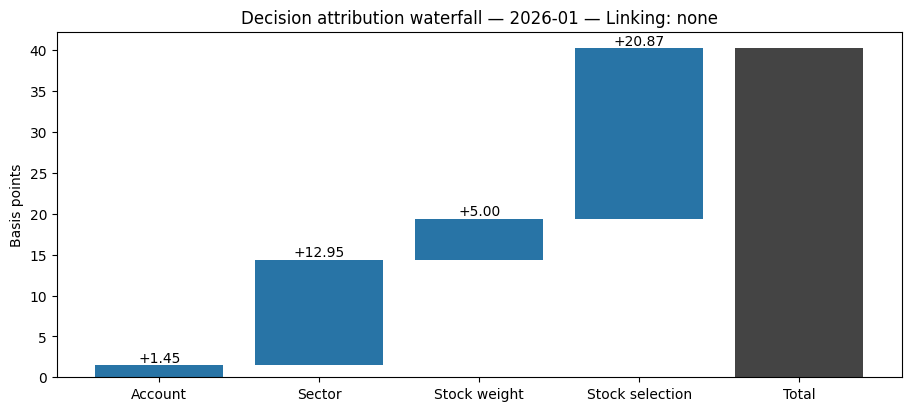

In [8]:
chosen = "2026-01"
row = decision.summary.filter(pl.col("period") == chosen).row(0, named=True)
stages = ["account_allocation", "sector_allocation", "security_allocation", "security_selection"]
labels = ["Account", "Sector", "Stock weight", "Stock selection"]
values = [row[name] * 10_000 for name in stages]
starts = [0.0]
for value in values[:-1]:
    starts.append(starts[-1] + value)
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
for i, (start, value) in enumerate(zip(starts, values)):
    ax.bar(i, value, bottom=start, color="#2874a6" if value >= 0 else "#c0392b")
    ax.text(i, start + value, f"{value:+.2f}", ha="center", va="bottom" if value >= 0 else "top")
ax.bar(len(values), row["excess_return"] * 10_000, color="#444", label="Total excess")
ax.set_xticks(range(len(values) + 1), labels + ["Total"])
ax.axhline(0, color="black", lw=.7)
ax.set_ylabel("Basis points")
ax.set_title(f"Decision attribution waterfall — {chosen} — Linking: none")
plt.show()

## Three methods: same total return, different decision explanations

In [9]:
comparison = macro_micro.integrated_summary.select(
    "period", pl.col("account_allocation").alias("macro_account_allocation"),
    pl.col("excess_return").alias("macro_excess")
).join(pooled.summary.select(
    "period", pl.col("allocation").alias("pooled_sector_allocation"),
    pl.col("excess_return").alias("pooled_excess")
), on="period").join(decision.summary.select(
    "period", "account_allocation", "sector_allocation", "security_allocation",
    "security_selection", pl.col("excess_return").alias("decision_excess")
), on="period").sort("period")
display(comparison)
assert comparison.select(
    ((pl.col("macro_excess")-pl.col("pooled_excess")).abs() < 1e-12).all().alias("pooled_ok"),
    ((pl.col("macro_excess")-pl.col("decision_excess")).abs() < 1e-12).all().alias("decision_ok"),
).row(0) == (True, True)

period,macro_account_allocation,macro_excess,pooled_sector_allocation,pooled_excess,account_allocation,sector_allocation,security_allocation,security_selection,decision_excess
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""2026-01""",0.000145,0.004027,0.001408,0.004027,0.000145,0.001295,0.0005,0.002087,0.004027
"""2026-02""",-0.000085,-0.000614,-0.002483,-0.000614,-0.000085,-0.002412,-0.000254,0.002136,-0.000614
"""2026-03""",0.0,0.004246,0.001993,0.004246,0.0,0.002007,0.000045,0.002194,0.004246


## Multiple-period linking: select and label each method explicitly

The table compares four arithmetic linkers on the **same three periods**. All three views agree on compounded total excess, but distribute effects differently. `link_macro_micro_attribution` and `link_hierarchical_decision_attribution` apply one period factor to every additive effect in that period. Geometric linking has a different multiplicative target and cannot be used on these two additive stage tables.

In [10]:
linkers = [link_carino, link_grap, link_frongello, link_menchero]
linked_runs = {}
rows = []
for linker in linkers:
    method = linker.__name__.removeprefix("link_").title()
    macro_linked = link_macro_micro_attribution(macro_micro, linking=linker)
    decision_linked = link_hierarchical_decision_attribution(decision, linking=linker)
    pooled_linked = linker(pooled)
    linked_runs[method] = (macro_linked, decision_linked, pooled_linked)
    rows.append({
        "Linking method": method,
        "Macro→Micro excess (bp)": 10_000 * macro_linked.summary["excess_return"][0],
        "Pooled excess (bp)": 10_000 * pooled_linked.summary["excess_return"][0],
        "Decision excess (bp)": 10_000 * decision_linked.summary["excess_return"][0],
        "Macro account allocation (bp)": 10_000 * macro_linked.summary["account_allocation"][0],
        "Decision account allocation (bp)": 10_000 * decision_linked.summary["account_allocation"][0],
    })
linked_comparison = pl.DataFrame(rows)
display(linked_comparison)
assert linked_comparison.select((pl.col("Macro→Micro excess (bp)")-
                                 pl.col("Decision excess (bp)")).abs().max()).item() < 1e-8

Linking method,Macro→Micro excess (bp),Pooled excess (bp),Decision excess (bp),Macro account allocation (bp),Decision account allocation (bp)
str,f64,f64,f64,f64,f64
"""Carino""",78.10224,78.10224,78.10224,0.586209,0.586209
"""Grap""",78.10224,78.10224,78.10224,0.583702,0.583702
"""Frongello""",78.10224,78.10224,78.10224,0.583702,0.583702
"""Menchero""",78.10224,78.10224,78.10224,0.602856,0.602856


### Multiple-period comparison chart (every legend names the linking method)

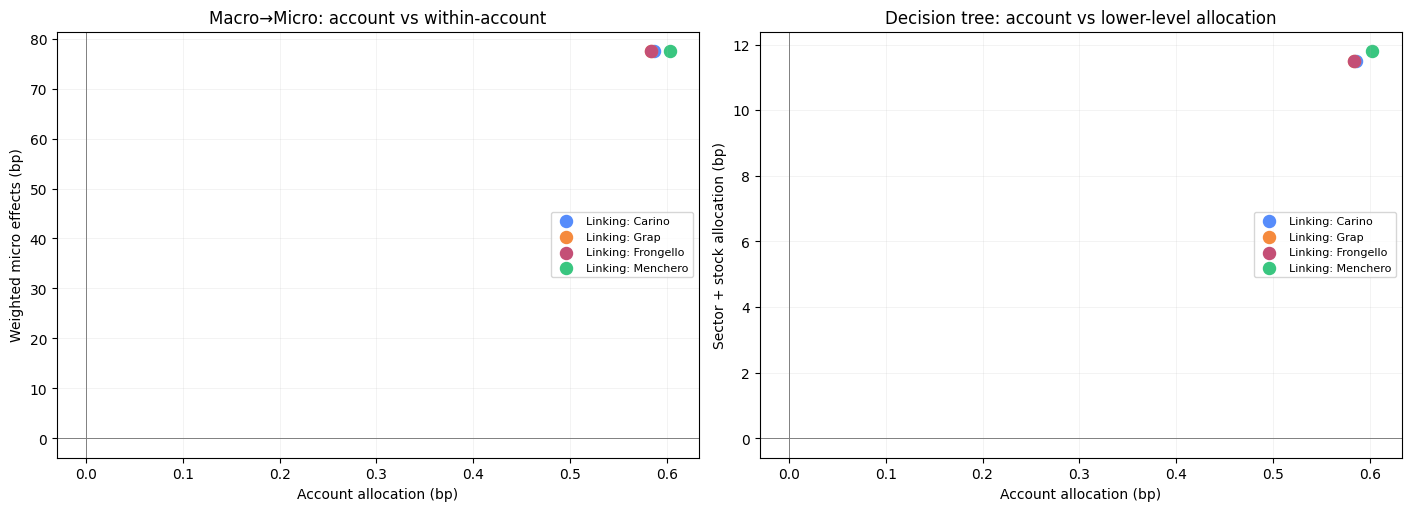

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
for method, (macro_linked, decision_linked, _) in linked_runs.items():
    ms = macro_linked.summary.row(0, named=True)
    ds = decision_linked.summary.row(0, named=True)
    axes[0].scatter(10_000 * ms["account_allocation"],
                    10_000 * sum(ms[x] for x in ["weighted_micro_allocation",
                                                "weighted_micro_selection", "weighted_micro_interaction"]),
                    s=75, label=f"Linking: {method}")
    axes[1].scatter(10_000 * ds["account_allocation"],
                    10_000 * (ds["sector_allocation"] + ds["security_allocation"]),
                    s=75, label=f"Linking: {method}")
axes[0].set(title="Macro→Micro: account vs within-account", xlabel="Account allocation (bp)",
            ylabel="Weighted micro effects (bp)")
axes[1].set(title="Decision tree: account vs lower-level allocation",
            xlabel="Account allocation (bp)", ylabel="Sector + stock allocation (bp)")
for ax in axes:
    ax.axhline(0, color="gray", lw=.7)
    ax.axvline(0, color="gray", lw=.7)
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)
plt.show()

## Interpretation boundaries

- Accounts and sectors need a defined conditional benchmark; an entire account or sector with zero benchmark notional raises an error.
- Transfers, fees, cash flows and intraperiod weight changes require upstream measurement and effective-date data. This example uses beginning notionals, not weights inferred from ending market values.
- The three methods can agree on total return while assigning allocation and selection differently. State the decision order and linking method in any report.